In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

## Loading and merging data

In [2]:
df = pd.read_csv('data/cleaned_public_transport.csv')
traffic = pd.read_csv('data/cleaned_traffic.csv')
weather = pd.read_csv('data/cleaned_weather.csv')
districts = pd.read_csv('districts.csv')

for table in [df, traffic, weather]:
    table['timestamp'] = pd.to_datetime(table['timestamp'])

df = df.merge(traffic[['district_id', 'timestamp', 'traffic_volume', 'average_speed_kmh', 'congestion_index', 'road_incident_count', 'rush_hour_flag', 'weekend_flag']], on=['district_id', 'timestamp'], how='left', validate='one_to_one')
df = df.merge(weather[['district_id', 'timestamp', 'rainfall_mm', 'weather_condition']], on=['district_id', 'timestamp'], how='left', validate='one_to_one')
df = df.merge(districts[['district_id', 'district_name', 'road_capacity_index', 'population_density', 'public_transport_access_index']], on='district_id', how='left', validate='many_to_one')
df = df.sort_values('timestamp')
df['hour'] = df['timestamp'].dt.hour
df['day_of_week'] = df['timestamp'].dt.day_of_week

## Feature selection

In [3]:
selected_features = [
    'service_frequency', 'traffic_volume', 'average_speed_kmh',
    'congestion_index', 'road_incident_count', 'rush_hour_flag', 'weekend_flag',
    'rainfall_mm', 'weather_condition', 'district_name',
    'road_capacity_index', 'population_density',
    'public_transport_access_index', 'hour', 'day_of_week'
]
X = df[selected_features].copy()
y = df['service_disruption_flag']

## Train-test split

In [4]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

## Encoding, scaling, and correlation check

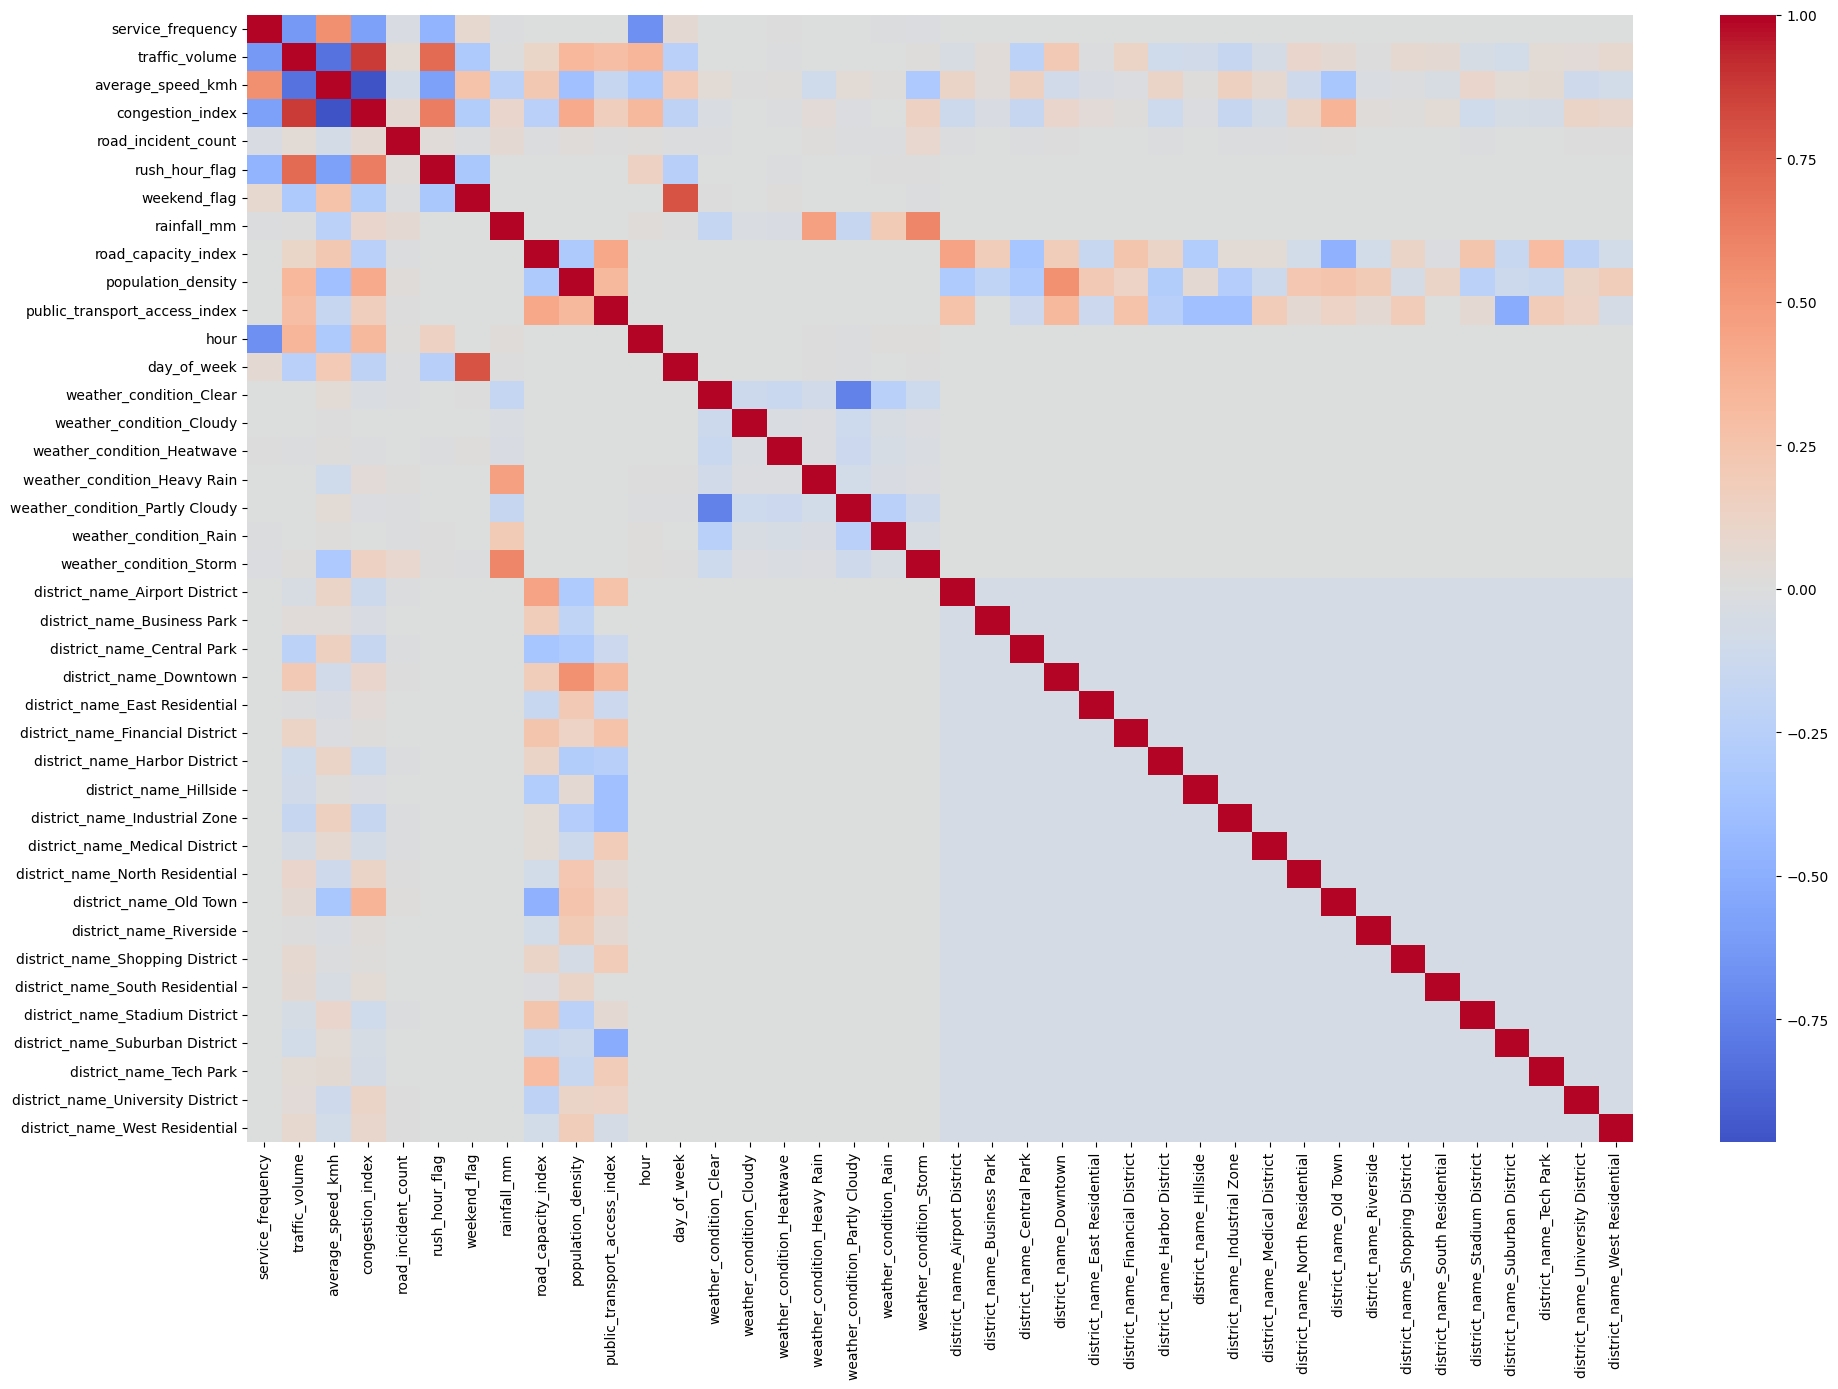

In [5]:
nominal_cols = ['weather_condition', 'district_name']
encoder = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
X_train_ohe = pd.DataFrame(encoder.fit_transform(X_train[nominal_cols]), columns=encoder.get_feature_names_out(nominal_cols), index=X_train.index)
X_test_ohe = pd.DataFrame(encoder.transform(X_test[nominal_cols]), columns=encoder.get_feature_names_out(nominal_cols), index=X_test.index)
X_train = pd.concat([X_train.drop(columns=nominal_cols), X_train_ohe], axis=1)
X_test = pd.concat([X_test.drop(columns=nominal_cols), X_test_ohe], axis=1)

scale_cols = X_train.select_dtypes(include=np.number).columns.tolist()
scaler = StandardScaler()
X_train[scale_cols] = scaler.fit_transform(X_train[scale_cols])
X_test[scale_cols] = scaler.transform(X_test[scale_cols])

correlation = X_train.corr()
plt.figure(figsize=(20, 14))
sns.heatmap(correlation, cmap='coolwarm', center=0)
plt.tight_layout()
plt.show()

high_corr_columns = ['congestion_index']
X_train = X_train.drop(columns=high_corr_columns)
X_test = X_test.drop(columns=high_corr_columns)

## Training and evaluation

In [6]:
model = LogisticRegression(max_iter=1000, class_weight='balanced')
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

print('Accuracy:', accuracy_score(y_test, y_pred))
print('Precision:', precision_score(y_test, y_pred))
print('Recall:', recall_score(y_test, y_pred))
print('F1 score:', f1_score(y_test, y_pred))

Accuracy: 0.9888990267639902
Precision: 1.0
Recall: 0.5993138936535163
F1 score: 0.7494637494637495
